24 files found


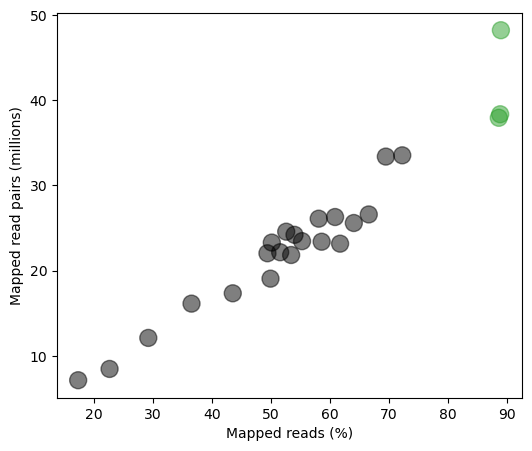

Ind25NT1      64.02%   25.59 M mapped
Ind25NT2      52.55%   24.57 M mapped
Ind25NT3      22.58%    8.45 M mapped
Ind25T251     72.24%   33.54 M mapped
Ind25T252     49.89%   19.05 M mapped
Ind25T253     17.25%    7.13 M mapped
Ind25T501     29.15%   12.09 M mapped
Ind25T502     43.48%   17.34 M mapped
Ind25T503     58.07%   26.10 M mapped
Ind5NT1       55.24%   23.46 M mapped
Ind5NT2       58.56%   23.40 M mapped
Ind5NT3       49.37%   22.04 M mapped
Ind5T251      36.48%   16.12 M mapped
Ind5T252      53.96%   24.21 M mapped
Ind5T253      66.56%   26.60 M mapped
Ind5T501      69.45%   33.39 M mapped
Ind5T502      60.84%   26.30 M mapped
Ind5T503      53.39%   21.83 M mapped
NI1           50.11%   23.29 M mapped
NI2           51.53%   22.16 M mapped
NI3           61.69%   23.16 M mapped
P1C20A4       88.98%   48.24 M mapped
P2C20A4       88.62%   37.95 M mapped
P3C20A4       88.85%   38.37 M mapped


In [2]:
import re
import glob
import matplotlib.pyplot as plt

files = sorted(glob.glob("messages/messages.*.err.txt"))
print(len(files), "files found")  # expect 24

pattern = re.compile(r"\[quant\] processed ([\d,]+) reads, ([\d,]+) reads pseudoaligned")

samples, pct_mapped, million_mapped = [], [], []

for f in files:
    sample = f.split("/")[-1].split(".")[1]  # "messages/messages.Ind25NT1.err.txt" -> "Ind25NT1"
    with open(f) as fh:
        matches = pattern.findall(fh.read())

    assert len(matches) == 3, f"{f}: found {len(matches)} kallisto runs, expected 3"

    # Third run = unstranded
    processed, aligned = (int(x.replace(",", "")) for x in matches[2])

    samples.append(sample)
    pct_mapped.append(100 * aligned / processed)
    million_mapped.append(aligned / 1e6)  # = (pct/100) * processed / 1e6

colors = ["tab:green" if "C20A4" in s else "black" for s in samples]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(pct_mapped, million_mapped, c=colors, s=150, alpha=0.5)
ax.set_xlabel("Mapped reads (%)")
ax.set_ylabel("Mapped read pairs (millions)")
plt.show()

for s, p, m in zip(samples, pct_mapped, million_mapped):
    print(f"{s:12s} {p:6.2f}%  {m:6.2f} M mapped")